# 10 — Direct Over/Under and BTTS prediction

**Question:** notebook 09 found that Poisson expected goals are well predicted, but the Over/Under
and BTTS probabilities derived from them are no better than league-wide frequencies, too extreme,
and too low for BTTS. Can models trained **directly** on each yes/no event do better? And can a
simple **past-only recalibration** repair the Poisson probabilities?

**Methods, all scored on the same 2,660 fixtures (2018-19 to 2024-25):**

| Method | What it is |
|---|---|
| Event frequency | share of training matches with the event, Jeffreys-smoothed `(k + 0.5) / (n + 1)` |
| League average, Team attack/defence, Poisson regression | the three Poisson forecasts of commit 15, recomputed with the same fold code |
| **Direct logistic** | one regularised Logistic Regression per event on the existing pre-match features |
| **Poisson regression, recalibrated** (separate experiment) | `sigmoid(a + b * logit(p))` fitted on earlier seasons' out-of-sample Poisson predictions |

**Walk-forward folds (season S):** fit candidates on seasons up to S-2, choose on S-1 (each event
chooses its own feature set — `goals` 30, `compact` 22 or `all` 50 — and `C` by log loss), refit
on seasons up to S-1, evaluate on S. Event frequencies use the same training seasons. 2025-26 and
2026-27 are never used. No new features; bookmaker odds are never a feature.

**Calibration chronology.** For season S the calibrator is fitted on the Poisson regression's
walk-forward predictions for S-3, S-2 and S-1. Each of those came from its own fold that never saw
the season it predicted, so the calibrator learns from genuine out-of-sample errors, and S itself
is never used. The base model is refitted every season, so the calibrator assumes the next fold
errs in the same way as recent folds. The 3-season window was fixed in advance, not tuned.

**Pre-specified decision rule** (`src/event_backtest.py`, written before the run). Primary
metrics: **Over 2.5 log loss** and **BTTS log loss**, judged separately. A candidate (direct
logistic, recalibrated Poisson) is ready for an event only if:
1. it beats the event frequency with a Bonferroni-adjusted interval below 0 (family of 8: 2
   candidates x 2 events x 2 comparators);
2. its pooled log loss is not higher than the best of the three commit-15 Poisson methods for
   that event;
3. it beats the event frequency in at least 5 of 7 seasons and when any one season is left out;
4. it is calibrated: mean within 2 points of the observed share, slope between 0.8 and 1.2, at
   most 1 of 10 reliability bins outside its 95% interval.

**Contents:** 1. Event base rates · 2. What the direct models chose · 3. Probability consistency ·
4. Pooled and per-season results · 5. Calibration · 6. The recalibration experiment · 7.
Statistical uncertainty · 8. Decision and conclusions

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from src.backtest import BACKTEST_SEASONS
from src.config import FIGURES_DIR
from src.event_backtest import (
    CANDIDATES, DIRECT, EVENTS_DIR, FREQUENCY, MAIN_METHODS, METHODS, POISSON_METHODS, RECALIBRATED,
    RULE_COMPARISONS, best_poisson, calibration_table, compare, correction_effect, crossing_table, event_losses,
    load_event_backtest, metric_label, pooled_metrics, readiness, rule_comparisons, run_event_backtest,
    save_event_backtest, season_metrics, season_sensitivity,
)
from src.event_models import EVENT_NAMES, OVER_EVENTS, PRIMARY_EVENTS, DirectEventClassifier, EventChoice, event_targets
from src.feature_engineering import load_features
from src.goals_backtest import (
    GOALS_DIR, LEAGUE, MARKET, MODEL, TEAM, bootstrap_means, load_goals_backtest, market_over_under, reliability_table,
)
from src.goals_model import EVENTS, GOALS_FEATURE_SETS, played
from src.train import VALIDATION_SEASON, season_name

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
history = played(features[features["season_start"] < VALIDATION_SEASON])

if (EVENTS_DIR / "predictions.csv").exists():
    experiment = load_event_backtest()
    print("Loaded the saved experiment from outputs/events/ (python -m src.event_backtest)")
else:
    start = time.time()
    experiment = run_event_backtest(features, progress=print)
    save_event_backtest(experiment)
    print(f"Experiment finished in {(time.time() - start) / 60:.1f} minutes")

predictions = experiment.predictions
assert set(predictions["season"]) == set(BACKTEST_SEASONS) and predictions["season"].max() < VALIDATION_SEASON
N_RESAMPLES = 10_000
SEASON_LABELS = {s: season_name(s) for s in BACKTEST_SEASONS}

# The recomputed Poisson forecasts must match the saved commit-15 run exactly
if (GOALS_DIR / "predictions.csv").exists():
    saved = load_goals_backtest().predictions
    keys = ["season", "method", "date", "home_team", "away_team"]
    mine = predictions[predictions["method"].isin(POISSON_METHODS)].sort_values(keys).reset_index(drop=True)
    theirs = saved.sort_values(keys).reset_index(drop=True)
    assert mine[keys].astype(str).equals(theirs[keys].astype(str))
    gap = np.abs(mine[EVENT_NAMES].to_numpy() - theirs[EVENT_NAMES].to_numpy()).max()
    print(f"Poisson forecasts match the commit-15 results (largest difference {gap:.1e})")
print(f"{(predictions['method'] == DIRECT).sum():,} fixtures x {predictions['method'].nunique()} methods")

Loaded the saved experiment from outputs/events/ (python -m src.event_backtest)
Poisson forecasts match the commit-15 results (largest difference 0.0e+00)
2,660 fixtures x 6 methods


In [2]:
# --- Chart style (same as notebooks 01-09) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE_LINE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#a3a29b"
COLORS = {MODEL: "#2a78d6", TEAM: "#eb6834", DIRECT: "#1baf7a", RECALIBRATED: "#c44e9b", LEAGUE: NEUTRAL,
          FREQUENCY: INK_2}
STYLE = {LEAGUE: "--", FREQUENCY: ":"}
EVENT_COLORS = dict(zip(EVENT_NAMES, ["#a3a29b", "#eb6834", "#2a78d6", "#1baf7a", "#c44e9b"]))


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")


def legend(ax, **kwargs):
    return ax.legend(**({"frameon": False, "fontsize": 8, "labelcolor": INK_2} | kwargs))


def season_axis(ax):
    ax.set_xticks(range(len(BACKTEST_SEASONS)))
    ax.set_xticklabels([SEASON_LABELS[s] for s in BACKTEST_SEASONS], rotation=45, ha="right")

## 1. Event base rates

How often does each event happen, and how stable is that over time? A forecast that always says
the long-run share is the natural floor. The direct models and the Poisson forecasts must beat it.

In [3]:
targets = event_targets(history).groupby(history["season_start"]).mean()
backtest_rates = targets.loc[list(BACKTEST_SEASONS)]
frequency_used = experiment.folds.set_index("season")[[f"frequency_{e}" for e in EVENT_NAMES]]
frequency_used.columns = EVENT_NAMES
view = pd.concat({"observed": backtest_rates, "event frequency forecast": frequency_used}, axis=1)
view.index = view.index.map(season_name)
display(view.style.format("{:.1%}").set_caption("Observed share of each event and the frequency baseline's forecast"))

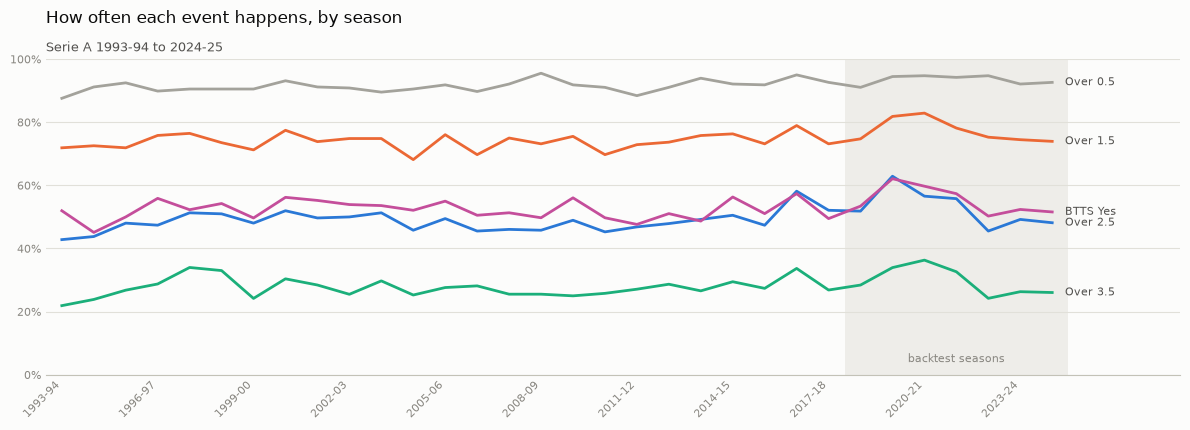

In [4]:
# Figure 57: event rates by season
fig, ax = plt.subplots(figsize=(12, 4.4))
fig.patch.set_facecolor(SURFACE)
x = targets.index
for event in EVENT_NAMES:
    ax.plot(x, targets[event], color=EVENT_COLORS[event], linewidth=2, label=EVENTS[event])
    ax.text(x[-1] + 0.4, targets[event].iloc[-1], EVENTS[event], fontsize=8, color=INK_2, va="center")
ax.axvspan(2017.5, 2024.5, color=GRID, alpha=0.5, linewidth=0)
ax.text(2021, 0.04, "backtest seasons", ha="center", fontsize=8, color=MUTED)
style_axes(ax)
ax.set_ylim(0, 1)
ax.set_xlim(x.min() - 0.5, x.max() + 4)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xticks(x[::3])
ax.set_xticklabels([season_name(s) for s in x[::3]], rotation=45, ha="right")
set_title(ax, "How often each event happens, by season", "Serie A 1993-94 to 2024-25")
fig.tight_layout()
save_figure(fig, "57_event_rates_by_season.png")
plt.show()

**Interpretation**

- **The base rates move more than any fixture-level signal.** Over 2.5 happened in 45.5% to 62.9%
  of matches across the seven backtest seasons, and BTTS in 50.3% to 62.1%. The event-frequency
  forecast, built from every earlier season, stayed between 48.6% and 53.0% for both.
- **The scoring burst is hard for any forecast.** The high-scoring seasons 2019-20 to 2021-22 sit
  far above anything earlier in the data, so a forecast built on the past is too low there. Pooled
  over the seven seasons, the event frequency is 3.6 points too low on Over 2.5 and 2.6 points too
  low on BTTS. All methods face this drift.
- **Over 0.5 is almost certain** (91-95%), so it carries little information. Over 1.5 (about
  74-83%) and Over 3.5 (24-36%) sit between that and the coin-flip events, Over 2.5 and BTTS.

## 2. What the direct models chose

Each event's classifier picks its feature set and `C` (smaller = stronger L2 penalty, closer to
a constant forecast) by log loss on S-1, after fitting on seasons up to S-2.

In [5]:
folds = experiment.folds.copy()
choice = pd.DataFrame({EVENTS[e]: folds[f"{e}_feature_set"] + ", C=" + folds[f"{e}_C"].map("{:g}".format)
                       for e in EVENT_NAMES})
choice.index = folds["season"].map(season_name)
display(choice.style.set_caption("Feature set and C chosen per event and fold (earlier seasons only)"))
tuning = experiment.tuning
spread = tuning.groupby(["season", "event"])["log_loss"].agg(["min", "max"])
spread["range"] = spread["max"] - spread["min"]
print("Largest gap between the best and worst candidate on the tuning season, per event:")
print(spread.groupby("event")["range"].max().round(4).to_string())

,Over 0.5,Over 1.5,Over 2.5,Over 3.5,BTTS Yes
season,,,,,
2018-19,"goals, C=0.0001","all, C=0.0001","goals, C=0.0003","all, C=0.0001","compact, C=0.0001"
2019-20,"compact, C=0.003","compact, C=0.0001","goals, C=0.0003","goals, C=0.0003","goals, C=0.001"
2020-21,"all, C=1","goals, C=0.3","all, C=0.03","goals, C=0.003","all, C=1"
2021-22,"compact, C=0.001","goals, C=0.03","compact, C=0.1","all, C=0.1","goals, C=0.0003"
2022-23,"goals, C=0.001","goals, C=0.001","goals, C=0.0001","goals, C=1","all, C=0.001"
2023-24,"compact, C=1","compact, C=0.0001","all, C=0.0001","all, C=0.0001","compact, C=0.0001"
2024-25,"all, C=1","all, C=1","goals, C=1","goals, C=1","all, C=0.1"


Largest gap between the best and worst candidate on the tuning season, per event:
event
btts_yes    0.0154
over_0_5    0.0104
over_1_5    0.0182
over_2_5    0.0190
over_3_5    0.0114


In [6]:
# Coefficients of the latest fold's Over 2.5 and BTTS classifiers, refitted exactly as in the backtest
last = folds.iloc[-1]
latest = DirectEventClassifier({e: EventChoice(last[f"{e}_feature_set"], float(last[f"{e}_C"])) for e in EVENT_NAMES})
latest.fit(history[history["season_start"] <= int(last["season"]) - 1])
coefficients = pd.DataFrame({EVENTS[e]: latest.coefficients(e) for e in PRIMARY_EVENTS})
top = coefficients.abs().max(axis=1).sort_values(ascending=False).index[:10]
display(coefficients.loc[top].style.format("{:+.3f}", na_rep="").set_caption(
    f"Largest coefficients (log-odds per standard deviation) of the {season_name(int(last['season']))} fold"))

,Over 2.5,BTTS Yes
away_season_played,+0.605,+0.038
home_season_played,-0.539,+0.024
home_venue_form10_ppg,,-0.115
home_venue_form10_gf,+0.102,+0.050
away_form10_ppg,,+0.101
away_history_matches,+0.085,+0.031
home_form5_gf,+0.084,+0.046
home_venue_form5_ppg,,+0.083
away_venue_form10_ga,+0.082,+0.021
away_form5_ppg,,-0.077


**Interpretation**

- **No stable choice.** The feature set changes from fold to fold. `C` runs from 0.0001, which
  shrinks the model almost to a constant equal to the training share, to 1, a weak penalty.
- **The tuning season can hardly tell the candidates apart.** The best and worst candidate on
  S-1 differ by at most 0.019 in log loss, so these choices are close to noise.
- **A weakly penalised fold picks up spurious patterns.** The 2024-25 Over 2.5 classifier
  (`C = 1`) gives its two largest weights, with opposite signs, to `away_season_played` (+0.61) and
  `home_season_played` (-0.54). Two clubs have almost always played the same number of matches,
  so this is a collinear pair that cancels out, not a football signal. Its Over 2.5 log loss in
  2024-25 is slightly worse than the event frequency (0.6952 vs 0.6929).

## 3. Probability consistency

Independently trained classifiers can contradict each other, e.g. give Over 2.5 a higher
probability than Over 1.5 for the same fixture. That is impossible (every match with 3+ goals also
has 2+), so such fixtures are repaired with a documented, deterministic rule: the Over
probabilities are replaced by the closest non-increasing sequence in the least-squares sense
(isotonic regression; crossing neighbours are averaged). Fixtures that are already ordered are
untouched, and Under is always `1 - Over`. The same applies to the separately fitted calibrators.
BTTS is predicted on its own and is not part of the correction, and the direct models do **not**
form an exact-score distribution.

In [7]:
crossing = crossing_table(experiment)
view = crossing.pivot(index="season", columns="method", values=["crossing", "share", "mean_change_when_crossing"])
view.index = view.index.map(season_name)
display(view.style.format("{:.0f}", subset=pd.IndexSlice[:, ["crossing"]]).format(
    "{:.1%}", subset=pd.IndexSlice[:, ["share"]]).format("{:.4f}", subset=pd.IndexSlice[:, ["mean_change_when_crossing"]])
        .set_caption("Fixtures whose Over probabilities crossed before the correction"))
totals = crossing.groupby("method")[["fixtures", "crossing"]].sum()
totals["share"] = totals["crossing"] / totals["fixtures"]
display(totals.style.format({"share": "{:.2%}"}).set_caption("All seasons"))
effect = correction_effect(experiment)
display(effect.style.format({"log_loss_uncorrected": "{:.5f}", "log_loss_corrected": "{:.5f}", "difference": "{:+.6f}"})
        .hide(axis="index").set_caption("Pooled log loss before and after the correction (identical fixtures)"))

,fixtures,crossing,share
method,,,
Direct logistic,2660,0,0.00%
"Poisson regression, recalibrated",2660,0,0.00%


method,event,label,log_loss_uncorrected,log_loss_corrected,difference,fixtures_changed
Direct logistic,over_0_5,Over 0.5,0.24248,0.24248,+0.000000,0
Direct logistic,over_1_5,Over 1.5,0.53719,0.53719,+0.000000,0
Direct logistic,over_2_5,Over 2.5,0.69265,0.69265,+0.000000,0
Direct logistic,over_3_5,Over 3.5,0.60590,0.60590,+0.000000,0
"Poisson regression, recalibrated",over_0_5,Over 0.5,0.24359,0.24359,+0.000000,0
"Poisson regression, recalibrated",over_1_5,Over 1.5,0.53547,0.53547,+0.000000,0
"Poisson regression, recalibrated",over_2_5,Over 2.5,0.69078,0.69078,+0.000000,0
"Poisson regression, recalibrated",over_3_5,Over 3.5,0.60854,0.60854,+0.000000,0


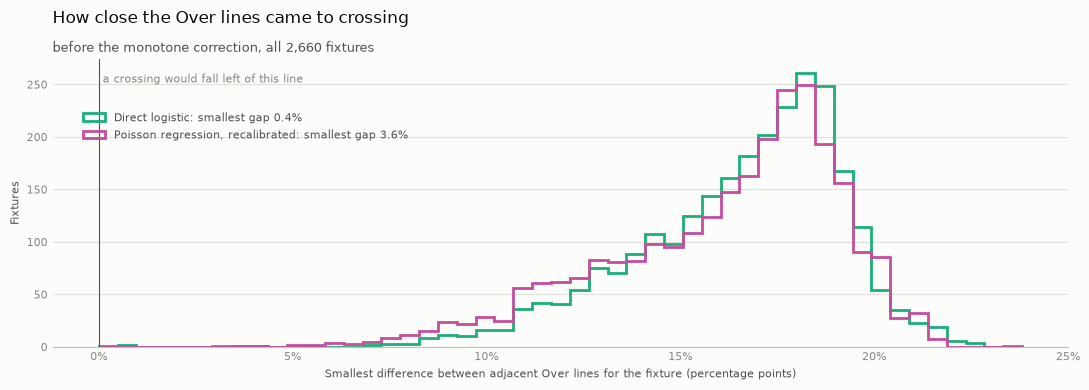

In [8]:
# Figure 58: how close the separately predicted Over lines came to crossing
raw = experiment.uncorrected
fig, ax = plt.subplots(figsize=(11, 4))
fig.patch.set_facecolor(SURFACE)
gaps = {}
for method in CANDIDATES:
    values = raw.loc[raw["method"] == method, OVER_EVENTS].to_numpy()
    gaps[method] = (values[:, :-1] - values[:, 1:]).min(axis=1)  # smallest drop between adjacent lines
top = max(g.max() for g in gaps.values())
bins = np.linspace(min(0.0, min(g.min() for g in gaps.values())), top, 50)
for method, gap in gaps.items():
    ax.hist(gap, bins=bins, histtype="step", linewidth=2, color=COLORS[method],
            label=f"{method}: smallest gap {gap.min():.1%}")
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.text(0, ax.get_ylim()[1] * 0.95, " a crossing would fall left of this line", fontsize=8, color=MUTED, va="top")
style_axes(ax)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Smallest difference between adjacent Over lines for the fixture (percentage points)", fontsize=8, color=INK_2)
ax.set_ylabel("Fixtures", fontsize=8, color=INK_2)
set_title(ax, "How close the Over lines came to crossing", "before the monotone correction, all 2,660 fixtures")
legend(ax, loc="upper left", bbox_to_anchor=(0.02, 0.85))
fig.tight_layout()
save_figure(fig, "58_over_line_gaps.png")
plt.show()

**Interpretation**

- **No fixture needed the correction.** In all 2,660 fixtures the separately trained Over
  classifiers (and the separately fitted calibrators) never crossed. So the correction changed no
  probability, and the validation scores before and after it are identical.
- **The direct models came close, though.** The smallest gap between adjacent lines was 0.35
  points (between Over 2.5 and Over 3.5), so crossings are possible with other settings or
  features. The correction stays in place and is tested on deliberately crossing inputs (it equals
  scikit-learn's isotonic regression). The recalibrated Poisson lines never came closer than
  3.6 points.
- **Why there were no crossings:** each line's base rate is very different (about 93%, 76%, 53%
  and 30%), and the classifiers' fixture-to-fixture variation is small compared with those gaps.

## 4. Pooled and per-season results

Log loss (`-log` of the probability given to what happened) and the binary Brier score, for every
event and method, on identical fixtures. Lower is better. The recalibrated Poisson regression is a
separate experiment and is listed last.

In [9]:
pooled = pooled_metrics(predictions)
ll = pooled[[f"log_loss_{e}" for e in EVENT_NAMES]].rename(columns=lambda c: EVENTS[c.removeprefix("log_loss_")])
br = pooled[[f"brier_{e}" for e in EVENT_NAMES]].rename(columns=lambda c: EVENTS[c.removeprefix("brier_")])
display(ll.style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
        .set_caption("Pooled log loss, 2018-19 to 2024-25 (bold = best per event)"))
display(br.style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold").set_caption("Pooled Brier score"))
for event in PRIMARY_EVENTS:
    print(f"Best existing Poisson method for {EVENTS[event]}: {best_poisson(predictions, event)}")

,Over 0.5,Over 1.5,Over 2.5,Over 3.5,BTTS Yes
method,,,,,
Event frequency,0.2448,0.5380,0.6947,0.6094,0.6893
League average,0.2427,0.5381,0.6945,0.6099,0.6892
Team attack/defence,0.2449,0.5353,0.6918,0.6089,0.6895
Poisson regression,0.2425,0.5347,0.6912,0.6090,0.6900
Direct logistic,0.2425,0.5372,0.6926,0.6059,0.6877
"Poisson regression, recalibrated",0.2436,0.5355,0.6908,0.6085,0.6890


,Over 0.5,Over 1.5,Over 2.5,Over 3.5,BTTS Yes
method,,,,,
Event frequency,0.0618,0.1763,0.2508,0.2092,0.2481
League average,0.0615,0.1764,0.2507,0.2094,0.2480
Team attack/defence,0.0616,0.1753,0.2491,0.2092,0.2481
Poisson regression,0.0614,0.1751,0.2490,0.2091,0.2484
Direct logistic,0.0616,0.1761,0.2497,0.2077,0.2472
"Poisson regression, recalibrated",0.0615,0.1753,0.2488,0.2089,0.2479


Best existing Poisson method for Over 2.5: Poisson regression
Best existing Poisson method for BTTS Yes: League average


In [10]:
seasonal = season_metrics(predictions)
for event in PRIMARY_EVENTS:
    table = seasonal[f"log_loss_{event}"].unstack("method")[METHODS]
    table.index = table.index.map(season_name)
    display(table.style.format("{:.4f}").highlight_min(axis=1, props="font-weight: bold")
            .set_caption(f"{EVENTS[event]} log loss per season (bold = best)"))

method,Event frequency,League average,Team attack/defence,Poisson regression,Direct logistic,"Poisson regression, recalibrated"
season,,,,,,
2018-19,0.6946,0.6943,0.7082,0.6954,0.6891,0.6935
2019-20,0.7002,0.6991,0.6749,0.6797,0.6831,0.6705
2020-21,0.6952,0.6951,0.6960,0.6824,0.6850,0.6797
2021-22,0.6942,0.6939,0.6878,0.6931,0.7094,0.6892
2022-23,0.6928,0.6929,0.6950,0.6961,0.6923,0.7174
2023-24,0.6931,0.6931,0.6800,0.6967,0.6943,0.6937
2024-25,0.6929,0.6930,0.7007,0.6947,0.6952,0.6915


method,Event frequency,League average,Team attack/defence,Poisson regression,Direct logistic,"Poisson regression, recalibrated"
season,,,,,,
2018-19,0.6911,0.6911,0.7004,0.6880,0.6904,0.6889
2019-20,0.6835,0.6831,0.6706,0.6812,0.6710,0.6731
2020-21,0.6844,0.6842,0.6787,0.6903,0.6836,0.6817
2021-22,0.6863,0.6860,0.6769,0.6795,0.6802,0.6763
2022-23,0.6947,0.6949,0.7020,0.7007,0.6978,0.7146
2023-24,0.6921,0.6922,0.6949,0.6928,0.6903,0.6936
2024-25,0.6930,0.6932,0.7031,0.6973,0.7003,0.6945


In [11]:
# Context only: the betting market's Over/Under 2.5 on the same fixtures (never a feature)
odds = market_over_under(seasons=set(BACKTEST_SEASONS)).dropna(subset=["market_over_2_5"])
rows = predictions[["season", "method", "date", "home_team", "away_team", "home_goals", "away_goals", "over_2_5"]]
rows = rows.merge(odds[["date", "home_team", "away_team", "market_over_2_5"]], on=["date", "home_team", "away_team"])
y = (rows["home_goals"] + rows["away_goals"] > 2.5).astype(float)
def ll_of(p): return -(y * np.log(p) + (1 - y) * np.log(1 - p))
market_table = pd.DataFrame({m: [ll_of(rows["over_2_5"]).where(rows["method"] == m).mean(),
                                 int((rows["method"] == m).sum())] for m in METHODS}, index=["log_loss", "fixtures"]).T
market_table.loc[MARKET] = [ll_of(rows.loc[rows["method"] == DIRECT, "market_over_2_5"]).mean(),
                            int((rows["method"] == DIRECT).sum())]
display(market_table.style.format({"log_loss": "{:.4f}", "fixtures": "{:,.0f}"})
        .set_caption("Over 2.5 log loss on the fixtures with market odds (context, not part of the rule)"))

,log_loss,fixtures
Event frequency,0.6947,"2,658"
League average,0.6945,"2,658"
Team attack/defence,0.6918,"2,658"
Poisson regression,0.6912,"2,658"
Direct logistic,0.6927,"2,658"
"Poisson regression, recalibrated",0.6908,"2,658"
Market average (O/U 2.5),0.6786,"2,658"


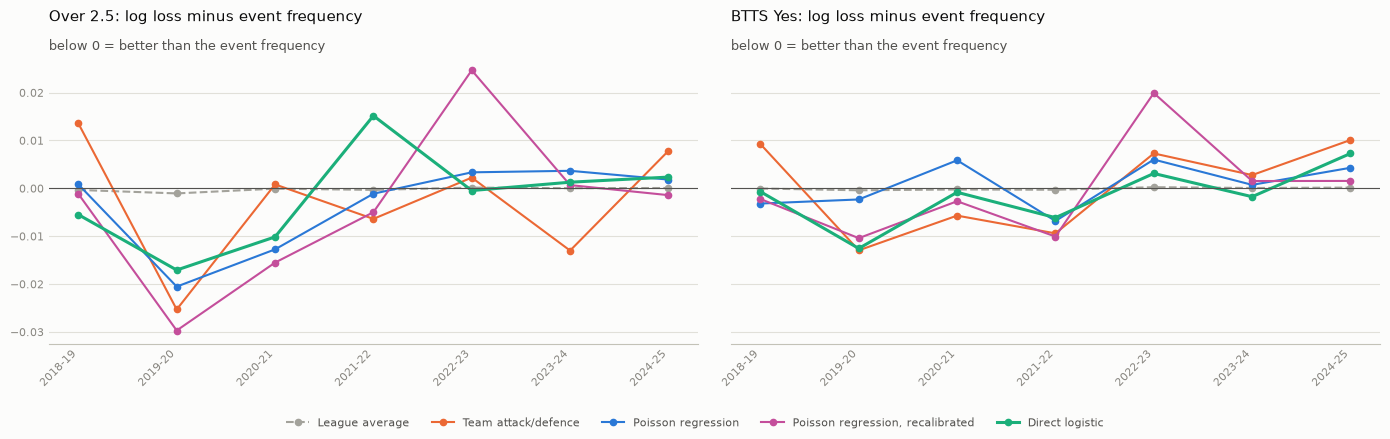

In [12]:
# Figure 59: per-season log loss minus the event frequency, Over 2.5 and BTTS
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
fig.patch.set_facecolor(SURFACE)
x = np.arange(len(BACKTEST_SEASONS))
for ax, event in zip(axes, PRIMARY_EVENTS):
    table = seasonal[f"log_loss_{event}"].unstack("method")
    for method in [LEAGUE, TEAM, MODEL, RECALIBRATED, DIRECT]:
        diff = (table[method] - table[FREQUENCY]).to_numpy()
        ax.plot(x, diff, marker="o", markersize=4.5, linewidth=2.2 if method == DIRECT else 1.5,
                linestyle=STYLE.get(method, "-"), color=COLORS[method], label=method)
    ax.axhline(0, color=INK_2, linewidth=0.8)
    style_axes(ax)
    season_axis(ax)
    set_title(ax, f"{EVENTS[event]}: log loss minus event frequency", "below 0 = better than the event frequency", size=11)
fig.tight_layout(rect=(0, 0.07, 1, 1))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=5, frameon=False, fontsize=8, labelcolor=INK_2)
save_figure(fig, "59_event_log_loss_by_season.png")
plt.show()

**Interpretation**

- **Over 2.5: the recalibrated Poisson regression has the lowest pooled log loss** (0.6908),
  just ahead of the original Poisson regression (0.6912). The direct logistic (0.6926) is *worse*
  than the Poisson regression, though still a little better than the event frequency (0.6947).
- **BTTS: the direct logistic is best** (0.6877). Every commit-15 Poisson method and the event
  frequency (0.6893) are slightly worse; the best of them is the league average at 0.6892.
- **On the other lines** the direct model leads Over 3.5 (0.6059 vs 0.6094 for the event
  frequency), and the Poisson regression leads Over 1.5 (0.5347). Over 0.5 is a tie (0.2425).
- **All differences are tiny:** a few thousandths of a log-loss unit, around a coin flip's 0.693.
  The betting market's Over 2.5 log loss is 0.6786 on the same fixtures, far ahead of every method
  here.
- **Most gains come from 2019-20 and 2020-21,** the high-scoring seasons the event frequency
  under-forecast.
- **2022-23 is the recalibration's worst season** (Over 2.5 0.7174, BTTS 0.7146). Its calibrator
  had just learned from the high-scoring 2019-22 seasons to push probabilities up, and then
  scoring fell. A calibrator trained on the past lags drift in the same way as the base rates.

## 5. Calibration

* **Mean vs observed:** is the average probability right?
* **Calibration slope and intercept:** a logistic regression of the outcome on `logit(p)`. Slope 1
  and intercept 0 are ideal; a slope below 1 means the probabilities are too extreme, above 1 too
  timid. Not estimated for forecasts that barely vary (event frequency, league average).
* **Reliability bins:** 10 equal-count bins by predicted probability, each with a 95% Wilson
  interval for the observed share.

In [13]:
calibration = calibration_table(predictions)
for event in PRIMARY_EVENTS:
    view = calibration[calibration["event"] == event].set_index("method")[
        ["mean_predicted", "observed", "difference", "calibration_intercept", "calibration_slope", "ece", "bins_outside"]]
    display(view.style.format({"mean_predicted": "{:.1%}", "observed": "{:.1%}", "difference": "{:+.1%}",
                               "calibration_intercept": "{:+.3f}", "calibration_slope": "{:.2f}", "ece": "{:.1%}",
                               "bins_outside": "{:.0f}"}, na_rep="-")
            .set_caption(f"{EVENTS[event]}: calibration (bins_outside of 10)"))
others = calibration[~calibration["event"].isin(PRIMARY_EVENTS)].pivot(index="method", columns="label",
                                                                       values="calibration_slope").reindex(METHODS)
display(others.style.format("{:.2f}", na_rep="-").set_caption("Calibration slope, other Over lines"))

,mean_predicted,observed,difference,calibration_intercept,calibration_slope,ece,bins_outside
method,,,,,,,
Event frequency,49.3%,52.9%,-3.6%,-,-,5.9%,5
League average,49.4%,52.9%,-3.4%,-,-,5.9%,5
Team attack/defence,52.5%,52.9%,-0.4%,+0.065,0.49,4.5%,5
Poisson regression,51.8%,52.9%,-1.1%,+0.077,0.53,4.6%,3
Direct logistic,51.2%,52.9%,-1.6%,+0.092,0.45,3.7%,3
"Poisson regression, recalibrated",54.3%,52.9%,+1.4%,+0.009,0.61,3.6%,1


,mean_predicted,observed,difference,calibration_intercept,calibration_slope,ece,bins_outside
method,,,,,,,
Event frequency,52.7%,55.3%,-2.6%,-,-,4.5%,3
League average,52.8%,55.3%,-2.4%,-,-,4.5%,3
Team attack/defence,52.5%,55.3%,-2.8%,+0.163,0.48,3.9%,2
Poisson regression,51.5%,55.3%,-3.8%,+0.177,0.58,3.8%,1
Direct logistic,53.9%,55.3%,-1.3%,+0.124,0.55,2.7%,2
"Poisson regression, recalibrated",55.7%,55.3%,+0.4%,+0.148,0.27,2.6%,1


label,Over 0.5,Over 1.5,Over 3.5
method,,,
Event frequency,-,-,-
League average,-,-,-
Team attack/defence,0.31,0.51,0.49
Poisson regression,0.52,0.62,0.46
Direct logistic,0.65,0.38,0.72
"Poisson regression, recalibrated",0.19,0.47,0.48


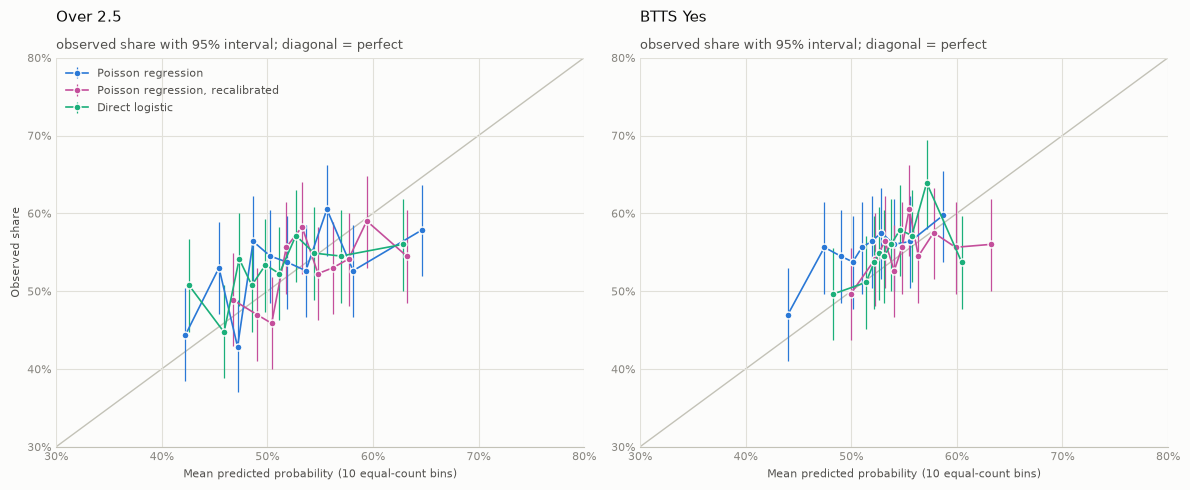

In [14]:
# Figure 60: reliability diagrams for Over 2.5 and BTTS
targets_eval = event_targets(predictions)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(SURFACE)
for ax, event in zip(axes, PRIMARY_EVENTS):
    for method in (MODEL, RECALIBRATED, DIRECT):
        mask = predictions["method"] == method
        table = reliability_table(predictions.loc[mask, event], targets_eval.loc[mask, event])
        ax.errorbar(table["mean_predicted"], table["observed"],
                    yerr=[table["observed"] - table["ci_low"], table["ci_high"] - table["observed"]],
                    fmt="o-", color=COLORS[method], markersize=5, linewidth=1.2, elinewidth=0.9, capsize=0,
                    markeredgecolor=SURFACE, markeredgewidth=1, label=method)
    ax.plot([0.3, 0.8], [0.3, 0.8], color=BASELINE_LINE, linewidth=1, zorder=0)
    style_axes(ax, grid="both")
    ax.set_xlim(0.3, 0.8)
    ax.set_ylim(0.3, 0.8)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Mean predicted probability (10 equal-count bins)", fontsize=8, color=INK_2)
    set_title(ax, EVENTS[event], "observed share with 95% interval; diagonal = perfect", size=11)
axes[0].set_ylabel("Observed share", fontsize=8, color=INK_2)
legend(axes[0], loc="upper left")
fig.tight_layout()
save_figure(fig, "60_event_reliability.png")
plt.show()

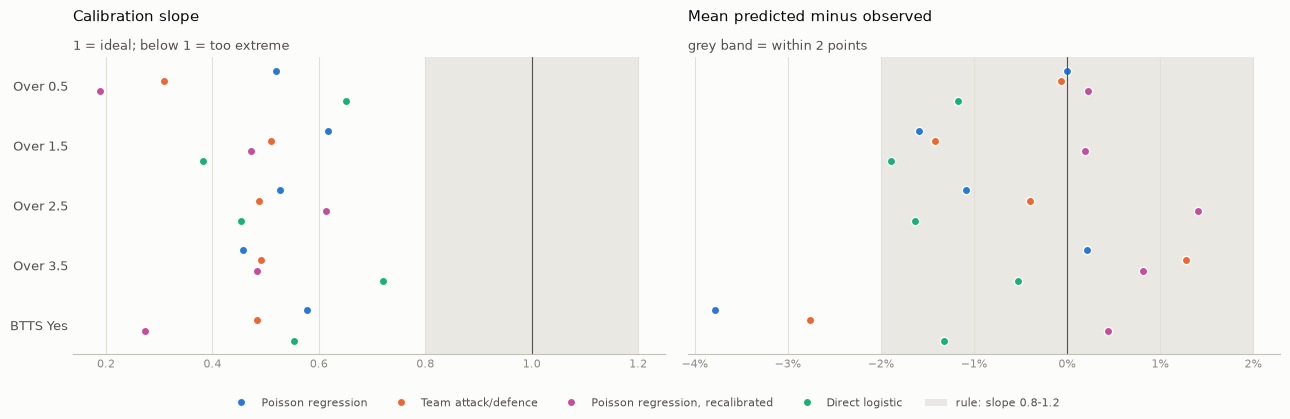

In [15]:
# Figure 61: calibration slope and mean-minus-observed for every event
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
fig.patch.set_facecolor(SURFACE)
y = np.arange(len(EVENT_NAMES))
shown = [MODEL, TEAM, RECALIBRATED, DIRECT]
for k, method in enumerate(shown):
    rows = calibration[calibration["method"] == method].set_index("event").loc[EVENT_NAMES]
    offset = (k - 1.5) * 0.17
    ax1.plot(rows["calibration_slope"], y + offset, "o", color=COLORS[method], markersize=6, markeredgecolor=SURFACE,
             label=method)
    ax2.plot(rows["difference"], y + offset, "o", color=COLORS[method], markersize=6, markeredgecolor=SURFACE)
ax1.axvspan(0.8, 1.2, color=GRID, alpha=0.7, linewidth=0, label="rule: slope 0.8-1.2")
ax1.axvline(1, color=INK_2, linewidth=0.8)
ax2.axvspan(-0.02, 0.02, color=GRID, alpha=0.7, linewidth=0)
ax2.axvline(0, color=INK_2, linewidth=0.8)
for ax in (ax1, ax2):
    style_axes(ax, grid="x")
ax1.set_yticks(y)
ax1.set_yticklabels([EVENTS[e] for e in EVENT_NAMES], color=INK_2, fontsize=9)
ax1.invert_yaxis()
ax2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
set_title(ax1, "Calibration slope", "1 = ideal; below 1 = too extreme", size=11)
set_title(ax2, "Mean predicted minus observed", "grey band = within 2 points", size=11)
fig.tight_layout(rect=(0, 0.07, 1, 1))
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=5, frameon=False, fontsize=8, labelcolor=INK_2)
save_figure(fig, "61_event_calibration_summary.png")
plt.show()

**Interpretation**

- **Every method's probabilities are too extreme.** All calibration slopes are well below the
  0.8-1.2 the rule asks for:
  - Over 2.5: direct logistic 0.45, Poisson regression 0.53, recalibrated 0.61;
  - BTTS: direct logistic 0.55, Poisson regression 0.58, recalibrated 0.27.

  The probabilities move between fixtures more than the outcomes justify. Part of this is
  season-level drift: a pooled slope also penalises forecasts whose average is off in a given season.
- **The recalibration fixes the average, not the spread:**
  - BTTS goes from 3.8 points too low (Poisson regression) to 0.4 points too high;
  - Over 2.5 now has only 1 of 10 reliability bins outside its interval (3 before).

  The slopes do not improve: the calibrator shrinks the spread, and what remains varies mainly with
  season-level shifts that did not repeat in the next season.
- **The direct logistic's averages are acceptable** (1.6 points too low for Over 2.5, 1.3 for BTTS),
  but 3 and 2 bins are outside their intervals and the slopes fail.

## 6. The recalibration experiment

Each season's calibrator is learned from the three previous seasons' out-of-sample Poisson
regression predictions. Its slope says how much the Poisson probabilities had to be pulled toward
the middle (`b < 1`) and its intercept how much they had to be shifted.

In [16]:
calibrators = experiment.calibrators.copy()
view = calibrators.pivot(index="season", columns="event", values=["slope", "intercept"])
view.index = view.index.map(season_name)
display(view.style.format("{:.2f}").set_caption("Calibrator slope and intercept per evaluation season (from S-3..S-1)"))
print("Calibration matches per season:", calibrators.groupby("season")["calibration_matches"].first().to_dict())
assert (calibrators["last_calibration_season"] < calibrators["season"]).all()

Calibration matches per season: {2018: 1140, 2019: 1140, 2020: 1140, 2021: 1140, 2022: 1140, 2023: 1140, 2024: 1140}


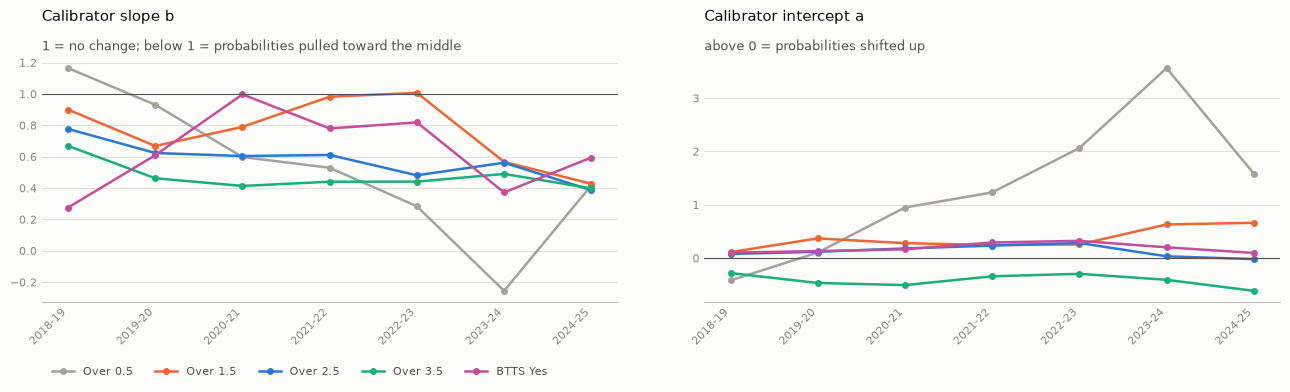

In [17]:
# Figure 62: calibrator coefficients over time
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
fig.patch.set_facecolor(SURFACE)
x = np.arange(len(BACKTEST_SEASONS))
for event in EVENT_NAMES:
    rows = calibrators[calibrators["event"] == event].set_index("season").loc[list(BACKTEST_SEASONS)]
    ax1.plot(x, rows["slope"], marker="o", markersize=4, linewidth=1.8, color=EVENT_COLORS[event], label=EVENTS[event])
    ax2.plot(x, rows["intercept"], marker="o", markersize=4, linewidth=1.8, color=EVENT_COLORS[event])
ax1.axhline(1, color=INK_2, linewidth=0.8)
ax2.axhline(0, color=INK_2, linewidth=0.8)
for ax in (ax1, ax2):
    style_axes(ax)
    season_axis(ax)
set_title(ax1, "Calibrator slope b", "1 = no change; below 1 = probabilities pulled toward the middle", size=11)
set_title(ax2, "Calibrator intercept a", "above 0 = probabilities shifted up", size=11)
legend(ax1, loc="upper left", bbox_to_anchor=(0, -0.22), ncols=5)
fig.tight_layout()
save_figure(fig, "62_recalibration_coefficients.png")
plt.show()

**Interpretation**

- **Persistent over-spread.** For Over 2.5 the calibrator's slope `b` stays between 0.39 and
  0.78 in every season, and between 0.40 and 0.67 for Over 3.5. Each season's past errors said the
  same thing: pull the Poisson probabilities toward the middle.
- **Upward shift.** The intercepts for Over 1.5, Over 2.5 and BTTS are mostly positive, which
  corrects the Poisson model's under-prediction of goals and BTTS.
- **Over 0.5 is unstable.** Its slope ranges from 1.16 to -0.26 and its intercept reaches 3.6.
  Over 0.5 fails only about 7% of the time and the Poisson probabilities barely vary, so three
  seasons (1,140 matches) cannot pin the calibrator down.
- **The assumption behind recalibration only partly holds.** The base model is refitted every
  season, but the calibrator assumes its errors repeat. The direction of the correction is stable;
  its size is not, and 2022-23 shows the cost when scoring changes.

## 7. Statistical uncertainty

Paired bootstrap of per-match log-loss differences on identical fixtures (10,000 resamples).

* **The decision family** (8 comparisons): each candidate against the event frequency and against
  the best commit-15 Poisson method, for Over 2.5 and BTTS, with Bonferroni-adjusted intervals
  (confidence 1 - 0.05/8) and Holm-adjusted p-values.
* **Secondary, exploratory:** the other Over lines and the Brier score, in their own family.
* **Season level:** seasons won, a sign test and the leave-one-season-out range.

In [18]:
family = rule_comparisons(predictions, n_resamples=N_RESAMPLES)
fmt = {c: "{:+.4f}" for c in ["difference", "ci_low", "ci_high", "adj_ci_low", "adj_ci_high"]} | {"p_holm": "{:.3f}"}
display(family[["a", "b", "label", "difference", "ci_low", "ci_high", "adj_ci_low", "adj_ci_high", "p_holm",
                "adjusted_interval_excludes_zero"]].style.format(fmt).hide(axis="index")
        .set_caption("Decision family: candidate minus comparator (negative = candidate better)"))
secondary_metrics = [f"log_loss_{e}" for e in EVENT_NAMES if e not in PRIMARY_EVENTS] + [f"brier_{e}" for e in EVENT_NAMES]
secondary = compare(predictions, [(c, FREQUENCY, m) for c in CANDIDATES for m in secondary_metrics]
                    + [(c, MODEL, m) for c in CANDIDATES for m in secondary_metrics], n_resamples=N_RESAMPLES)
display(secondary[["a", "b", "label", "difference", "ci_low", "ci_high", "adj_ci_high", "p_holm",
                   "adjusted_interval_excludes_zero"]].style.format(fmt).hide(axis="index")
        .set_caption(f"Secondary comparisons ({len(secondary)}, Bonferroni within this family)"))

a,b,label,difference,ci_low,ci_high,adj_ci_low,adj_ci_high,p_holm,adjusted_interval_excludes_zero
Direct logistic,Event frequency,"Log loss, Over 2.5",-0.0021,-0.0067,+0.0026,-0.0086,+0.0046,1.000,False
Direct logistic,Poisson regression,"Log loss, Over 2.5",+0.0015,-0.0018,+0.0048,-0.0031,+0.0061,1.000,False
Direct logistic,Event frequency,"Log loss, BTTS Yes",-0.0017,-0.0046,+0.0014,-0.0057,+0.0025,1.000,False
Direct logistic,League average,"Log loss, BTTS Yes",-0.0016,-0.0045,+0.0014,-0.0056,+0.0026,1.000,False
"Poisson regression, recalibrated",Event frequency,"Log loss, Over 2.5",-0.0039,-0.0092,+0.0013,-0.0113,+0.0036,1.000,False
"Poisson regression, recalibrated",Poisson regression,"Log loss, Over 2.5",-0.0004,-0.0037,+0.0029,-0.0049,+0.0041,1.000,False
"Poisson regression, recalibrated",Event frequency,"Log loss, BTTS Yes",-0.0004,-0.0041,+0.0033,-0.0053,+0.0047,1.000,False
"Poisson regression, recalibrated",League average,"Log loss, BTTS Yes",-0.0003,-0.0039,+0.0033,-0.0051,+0.0047,1.000,False


a,b,label,difference,ci_low,ci_high,adj_ci_high,p_holm,adjusted_interval_excludes_zero
Direct logistic,Event frequency,"Log loss, Over 0.5",-0.0023,-0.0053,+0.0008,+0.0028,1.000,False
Direct logistic,Event frequency,"Log loss, Over 1.5",-0.0008,-0.0044,+0.0027,+0.0052,1.000,False
Direct logistic,Event frequency,"Log loss, Over 3.5",-0.0035,-0.0077,+0.0008,+0.0032,1.000,False
Direct logistic,Event frequency,"Brier, Over 0.5",-0.0002,-0.0006,+0.0002,+0.0005,1.000,False
Direct logistic,Event frequency,"Brier, Over 1.5",-0.0002,-0.0015,+0.0011,+0.0019,1.000,False
Direct logistic,Event frequency,"Brier, Over 2.5",-0.0011,-0.0033,+0.0012,+0.0026,1.000,False
Direct logistic,Event frequency,"Brier, Over 3.5",-0.0015,-0.0033,+0.0003,+0.0013,1.000,False
Direct logistic,Event frequency,"Brier, BTTS Yes",-0.0009,-0.0023,+0.0006,+0.0016,1.000,False
"Poisson regression, recalibrated",Event frequency,"Log loss, Over 0.5",-0.0012,-0.0048,+0.0025,+0.0048,1.000,False
"Poisson regression, recalibrated",Event frequency,"Log loss, Over 1.5",-0.0026,-0.0071,+0.0021,+0.0046,1.000,False


In [19]:
pairs = [(c, FREQUENCY) for c in CANDIDATES] + [(c, MODEL) for c in CANDIDATES] + [(MODEL, FREQUENCY)]
sensitivity = season_sensitivity(predictions, pairs)
display(sensitivity.style.format({"sign_test_p": "{:.3f}", "pooled_difference": "{:+.4f}",
                                  "worst_season_difference": "{:+.4f}", "leave_one_out_min": "{:+.4f}",
                                  "leave_one_out_max": "{:+.4f}"}).hide(axis="index")
        .set_caption("Season-level consistency (negative = a better)"))

a,b,metric,label,seasons,seasons_better,sign_test_p,pooled_difference,worst_season_difference,leave_one_out_min,leave_one_out_max
Direct logistic,Event frequency,log_loss_over_2_5,"Log loss, Over 2.5",7,4,1.000,-0.0021,+0.0152,-0.0049,+0.0004
Direct logistic,Event frequency,log_loss_btts_yes,"Log loss, BTTS Yes",7,5,0.453,-0.0017,+0.0073,-0.0031,+0.0002
"Poisson regression, recalibrated",Event frequency,log_loss_over_2_5,"Log loss, Over 2.5",7,5,0.453,-0.0039,+0.0247,-0.0087,+0.0004
"Poisson regression, recalibrated",Event frequency,log_loss_btts_yes,"Log loss, BTTS Yes",7,4,1.000,-0.0004,+0.0199,-0.0037,+0.0013
Direct logistic,Poisson regression,log_loss_over_2_5,"Log loss, Over 2.5",7,3,1.000,+0.0015,+0.0163,-0.0010,+0.0028
Direct logistic,Poisson regression,log_loss_btts_yes,"Log loss, BTTS Yes",7,4,1.000,-0.0023,+0.0030,-0.0032,-0.0010
"Poisson regression, recalibrated",Poisson regression,log_loss_over_2_5,"Log loss, Over 2.5",7,6,0.125,-0.0004,+0.0213,-0.0040,+0.0011
"Poisson regression, recalibrated",Poisson regression,log_loss_btts_yes,"Log loss, BTTS Yes",7,4,1.000,-0.0010,+0.0139,-0.0035,+0.0003
Poisson regression,Event frequency,log_loss_over_2_5,"Log loss, Over 2.5",7,3,1.000,-0.0035,+0.0037,-0.0047,-0.0007
Poisson regression,Event frequency,log_loss_btts_yes,"Log loss, BTTS Yes",7,3,1.000,+0.0007,+0.0060,-0.0002,+0.0019


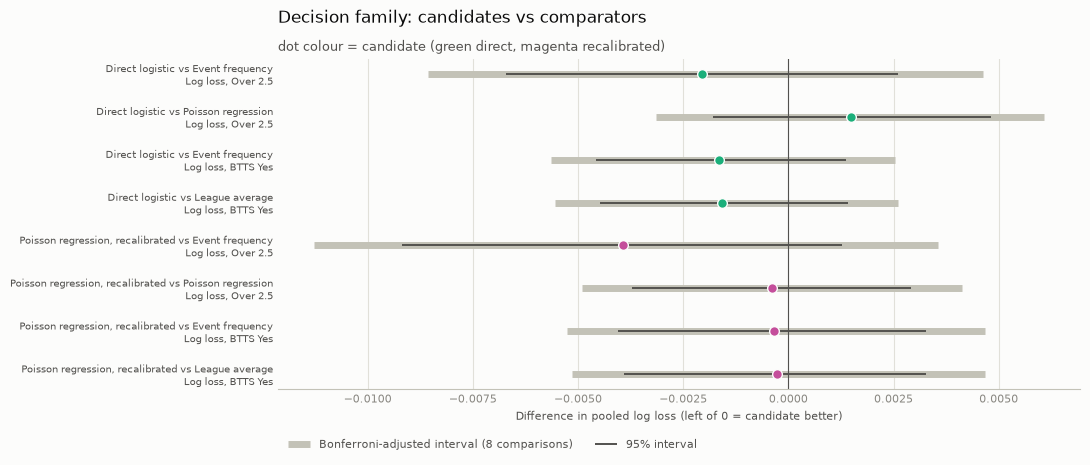

In [20]:
# Figure 63: forest plot of the decision family
fig, ax = plt.subplots(figsize=(11, 4.8))
fig.patch.set_facecolor(SURFACE)
labels = [f"{r.a} vs {r.b}\n{r.label}" for r in family.itertuples()]
y = np.arange(len(family))
ax.hlines(y, family["adj_ci_low"], family["adj_ci_high"], color=BASELINE_LINE, linewidth=5,
          label="Bonferroni-adjusted interval (8 comparisons)")
ax.hlines(y, family["ci_low"], family["ci_high"], color=INK_2, linewidth=1.4, label="95% interval")
for k, row in enumerate(family.itertuples()):
    ax.plot(row.difference, k, "o", color=COLORS[row.a], markersize=7, markeredgecolor=SURFACE)
ax.axvline(0, color=INK_2, linewidth=0.8)
style_axes(ax, grid="x")
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=7.5, color=INK_2)
ax.invert_yaxis()
ax.set_xlabel("Difference in pooled log loss (left of 0 = candidate better)", fontsize=8, color=INK_2)
set_title(ax, "Decision family: candidates vs comparators", "dot colour = candidate (green direct, magenta recalibrated)")
legend(ax, loc="upper left", bbox_to_anchor=(0, -0.12), ncols=2)
fig.tight_layout()
save_figure(fig, "63_event_decision_intervals.png")
plt.show()

**Interpretation**

- **None of the 8 decision comparisons excludes zero, even with the ordinary 95% interval.**
  - The largest gain over the event frequency is the recalibrated Poisson on Over 2.5: -0.0039,
    95% interval -0.0092 to +0.0013.
  - The direct BTTS model is -0.0017 (-0.0046 to +0.0014).
  - All Holm-adjusted p-values are 1.
- **None of the 32 secondary comparisons excludes zero either,** including the direct model's
  Over 3.5 gain (-0.0035, 95% interval -0.0077 to +0.0008).
- **The gains depend on one season.**
  - The direct BTTS model beats the event frequency in 5 of 7 seasons, but the gain disappears when
    2019-20 is left out (leave-one-out maximum +0.0002).
  - The recalibrated Over 2.5 model beats it in 5 of 7 seasons with the same dependence
    (+0.0004).
- **One consistent ordering, too small to establish.** Against the original Poisson regression,
  the direct BTTS model stays better whichever season is left out (-0.0032 to -0.0010). It wins
  only 4 of 7 seasons, and the interval includes zero.

## 8. Decision and conclusions

The rule from `src/event_backtest.py`, applied separately to Over 2.5 and BTTS for each candidate:

In [21]:
rule = readiness(predictions, n_resamples=N_RESAMPLES)
display(rule.style.format({"vs_frequency": "{:+.4f}", "vs_frequency_adj_ci_high": "{:+.4f}", "vs_best_poisson": "{:+.4f}",
                           "leave_one_out_max": "{:+.4f}", "mean_minus_observed": "{:+.1%}",
                           "calibration_slope": "{:.2f}"}).hide(axis="index"))

candidate,event,vs_frequency,vs_frequency_adj_ci_high,best_poisson,vs_best_poisson,seasons_better,leave_one_out_max,mean_minus_observed,calibration_slope,bins_outside,beats_frequency,competitive_with_poisson,consistent,calibrated,ready
Direct logistic,Over 2.5,-0.0021,+0.0046,Poisson regression,+0.0015,4,+0.0004,-1.6%,0.45,3,False,False,False,False,False
Direct logistic,BTTS Yes,-0.0017,+0.0025,League average,-0.0016,5,+0.0002,-1.3%,0.55,2,False,True,False,False,False
"Poisson regression, recalibrated",Over 2.5,-0.0039,+0.0036,Poisson regression,-0.0004,5,+0.0004,+1.4%,0.61,1,False,True,False,False,False
"Poisson regression, recalibrated",BTTS Yes,-0.0004,+0.0047,League average,-0.0003,4,+0.0013,+0.4%,0.27,1,False,True,False,False,False


**Results by event**

| | Event frequency | Best commit-15 Poisson | Poisson regression | Direct logistic | Recalibrated Poisson |
|---|---|---|---|---|---|
| Over 2.5 log loss | 0.6947 | 0.6912 (Poisson regression) | 0.6912 | 0.6926 | **0.6908** |
| BTTS log loss | 0.6893 | 0.6892 (league average) | 0.6900 | **0.6877** | 0.6890 |

- **Over 2.5:** the best method is the recalibrated Poisson regression.
  - It is better than the event frequency by 0.0039 and than the original Poisson regression by
    0.0004.
  - It fails the significance, consistency and calibration criteria (slope 0.61).
  - The direct logistic is worse than the Poisson regression on Over 2.5.
- **BTTS:** the best method is the direct logistic.
  - It is better than the event frequency by 0.0017 and than the best Poisson method by 0.0016,
    so it meets the "competitive" criterion.
  - It fails significance, the leave-one-season-out check and calibration (slope 0.55; 2 bins
    outside).

**Decision: neither event is ready, for either candidate.** No probabilities from this experiment
go into the app. The app keeps the historical goals frequencies from commit 14, labelled as history.

**What we learned**

1. **Training directly on the event does not unlock information.** The pre-match features (form,
   season and previous-season performance) say very little about goal totals or BTTS beyond the
   base rate. A direct classifier finds roughly the same small signal as the Poisson model.
2. **The largest source of error is season-level drift** in scoring. No method anticipates it,
   and a past-only calibrator lags it.
3. **Recalibration repairs averages, not discrimination.** The BTTS mean and the Over 2.5 bins
   improve, but the slopes stay far below 1.
4. **Consistency is not a practical problem with these settings.** The safeguard stays in place
   for future models.

**Limitations**

- **Sample size:** seven seasons and 2,660 fixtures cannot resolve differences of a few
  thousandths of a log-loss unit.
- **Noisy tuning:** each fold chooses its settings on a single season, and those choices are close
  to noise.
- **Pooled slopes mix two errors:** fixture-level over-spread and season-level shifts.
- **Fixed calibration window:** it is 3 seasons and was not tuned. A longer window would be more
  stable but lag drift even more.
- **No joint distribution:** the direct models give separate event probabilities, not an
  exact-score distribution. BTTS and the Over lines are not jointly consistent beyond the
  monotone Over correction.
- **Missing information:** lineups, injuries and team news are absent. This is the most likely
  reason the betting market is far ahead.

**Possible next steps** (not done here; no new features were added in this commit):
1. model the season scoring level explicitly, for example with a recency-weighted intercept;
2. choose the penalty on several past seasons rather than one;
3. study whether any goal-market forecast can approach the market without lineup information.

Each would need its own walk-forward test and a decision rule written in advance.